In [1]:
import pandas as pd

df = pd.read_csv("../data/superstore.csv", encoding="latin-1")
df.shape

(9994, 21)

In [2]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [6]:
print(df.duplicated().sum())
print(df.isna().sum().sum())

0
0


In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Postal Code"] = df["Postal Code"].astype(str).str.zfill(5)

In [10]:
print(df["Order Date"].min(), df["Order Date"].max())
print((df["Ship Date"] - df["Order Date"]).dt.days.describe())


2014-01-03 00:00:00 2017-12-30 00:00:00
count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
dtype: float64


In [11]:
df[["Order Date", "Ship Date", "Postal Code"]].dtypes

Order Date     datetime64[us]
Ship Date      datetime64[us]
Postal Code               str
dtype: object

In [13]:
weekly = (
    df.set_index("Order Date")
      .resample("W")
      .agg(
          sales=("Sales", "sum"),
          profit=("Profit", "sum"),
          orders=("Order ID", "nunique"),
          units=("Quantity", "sum"),
      )
)
weekly["margin"] = weekly["profit"] / weekly["sales"]
weekly["wow_sales_pct"] = weekly["sales"].pct_change() * 100
print(weekly.shape)
weekly.head()

(209, 6)


,sales,profit,orders,units,margin,wow_sales_pct
Order Date,,,,,,
2014-01-05,324.044,-55.5549,3,13,-0.171442,NaN
2014-01-12,4599.572,1322.7434,7,49,0.287580,1319.428226
2014-01-19,4509.127,398.8863,9,99,0.088462,-1.966379
2014-01-26,3842.388,758.0377,9,108,0.197283,-14.786432
2014-02-02,1642.310,239.5467,7,33,0.145860,-57.258091


0


<Axes: title={'center': 'Weekly sales'}, xlabel='Order Date'>

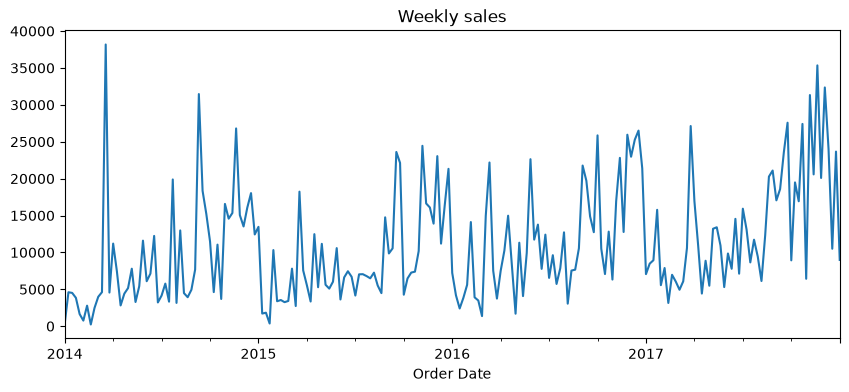

In [15]:
print((weekly["orders"] == 0).sum())
weekly["sales"].plot(figsize=(10, 4), title="Weekly sales")

In [17]:
by_cat = df.groupby("Category").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
)
by_cat["margin_pct"] = by_cat["profit"] / by_cat["sales"] * 100
by_cat.round(1).sort_values("profit", ascending=False)


,sales,profit,margin_pct
Category,,,
Technology,836154.0,145454.9,17.4
Office Supplies,719047.0,122490.8,17.0
Furniture,741999.8,18451.3,2.5


In [19]:
by_region = df.groupby("Region").agg(sales=("Sales", "sum"), profit=("Profit", "sum"))
by_region["margin_pct"] = by_region["profit"] / by_region["sales"] * 100
by_region.round(1).sort_values("profit", ascending=False)

,sales,profit,margin_pct
Region,,,
West,725457.8,108418.4,14.9
East,678781.2,91522.8,13.5
South,391721.9,46749.4,11.9
Central,501239.9,39706.4,7.9


In [22]:
df["discount_band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=["0%", "1-20%", "21-40%", ">40%"],
)
df.groupby("discount_band", observed=True).agg(
    orders=("Profit", "size"),
    avg_profit=("Profit", "mean"),
    total_profit=("Profit", "sum"),
).round(1)

,orders,avg_profit,total_profit
discount_band,,,
0%,4798,66.9,320987.6
1-20%,3803,26.5,100785.5
21-40%,460,-77.9,-35817.5
>40%,933,-106.7,-99558.6
